In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 646.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 6.9 MB/s eta 0:00:00


In [2]:
!pip install ultralytics

In [3]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.


In [4]:
model = YOLO("yolo11n.pt")

In [5]:
import os
import cv2

files = os.listdir("/content")
image_file = [f for f in files if f.lower().endswith((".png", ".jpg", ".jpeg"))][0]

image = cv2.imread("/content/" + image_file)

print("Image loaded:", image is not None)
print("Image shape:", image.shape)

Image loaded: True
Image shape: (1024, 1536, 3)


In [6]:
resized_image = cv2.resize(image, (640, 480))

print("Resized image shape:", resized_image.shape)

Resized image shape: (480, 640, 3)


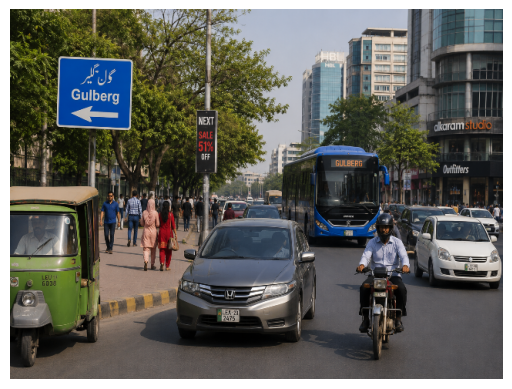

In [7]:
import matplotlib.pyplot as plt

plt.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [8]:
results = model(resized_image)

print("Object detection completed.")


0: 480x640 8 persons, 1 bicycle, 6 cars, 1 motorcycle, 1 bus, 1 truck, 294.0ms
Speed: 13.1ms preprocess, 294.0ms inference, 37.2ms postprocess per image at shape (1, 3, 480, 640)
Object detection completed.


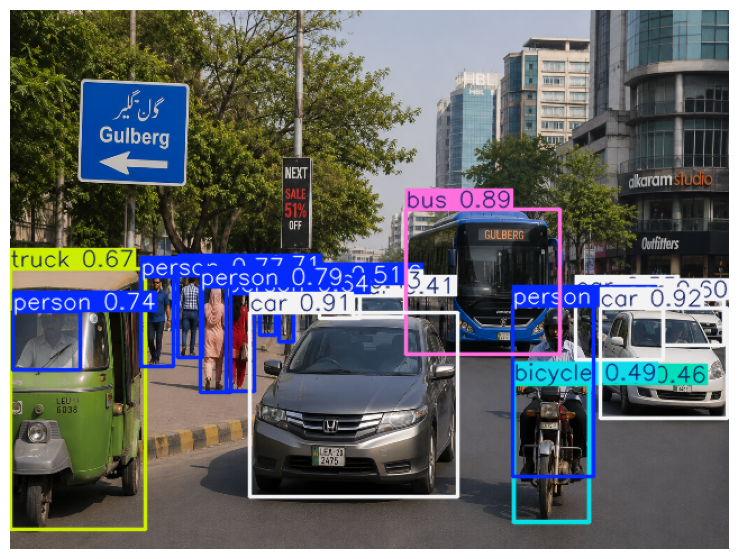

In [9]:
annotated_image = results[0].plot()

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [10]:
for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    class_name = model.names[class_id]

    print(f"{class_name}: {confidence:.2f}")

car: 0.92
car: 0.91
bus: 0.89
person: 0.82
person: 0.79
person: 0.77
person: 0.74
person: 0.71
truck: 0.67
person: 0.64
car: 0.60
car: 0.55
person: 0.51
bicycle: 0.49
motorcycle: 0.46
car: 0.43
car: 0.41
person: 0.26


In [11]:
cv2.imwrite("object_detection_result.jpg", annotated_image)

print("Detection result saved successfully.")

Detection result saved successfully.
